<a href="https://colab.research.google.com/github/bcarmoai/ML-and-AI/blob/main/TensorFlow_image_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 701s 4us/step


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 88s 55ms/step - accuracy: 0.4468 - loss: 1.5192 - val_accuracy: 0.5303 - val_loss: 1.2964
Epoch 2/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 78s 50ms/step - accuracy: 0.5854 - loss: 1.1675 - val_accuracy: 0.5965 - val_loss: 1.1190
Epoch 3/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 81s 49ms/step - accuracy: 0.6376 - loss: 1.0230 - val_accuracy: 0.6500 - val_loss: 0.9931
Epoch 4/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 81s 49ms/step - accuracy: 0.6747 - loss: 0.9209 - val_accuracy: 0.6528 - val_loss: 1.0017
Epoch 5/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 76s 48ms/step - accuracy: 0.7013 - loss: 0.8532 - val_accuracy: 0.6928 - val_loss: 0.8973
313/313 - 4s - 13ms/step - accuracy: 0.6928 - loss: 0.8973

Test accuracy: 0.6928
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step


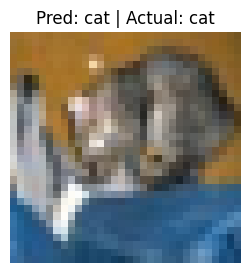

In [1]:
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt
import numpy as np

# 1. Load and preprocess the CIFAR-10 dataset
(train_images, train_labels), (test_images, test_labels) = datasets.cifar10.load_data()

# Normalize pixel values to be between 0 and 1
train_images, test_images = train_images / 255.0, test_images / 255.0

class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

# 2. Build the Convolutional Neural Network (CNN)
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10)
])

# 3. Compile the model
model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

# 4. Train the model (using 5 epochs for demonstration speed)
history = model.fit(train_images, train_labels, epochs=5,
                    validation_data=(test_images, test_labels))

# 5. Evaluate the model
test_loss, test_acc = model.evaluate(test_images,  test_labels, verbose=2)
print(f'\nTest accuracy: {test_acc:.4f}')

# 6. Make a prediction on a sample image
sample_index = 0
sample_image = test_images[sample_index]
actual_label = class_names[test_labels[sample_index][0]]

# Add batch dimension for the model prediction
predictions = model.predict(np.expand_dims(sample_image, axis=0))
predicted_label = class_names[np.argmax(predictions[0])]

# Plot the result
plt.figure(figsize=(3,3))
plt.imshow(sample_image)
plt.title(f"Pred: {predicted_label} | Actual: {actual_label}")
plt.axis('off')
plt.show()

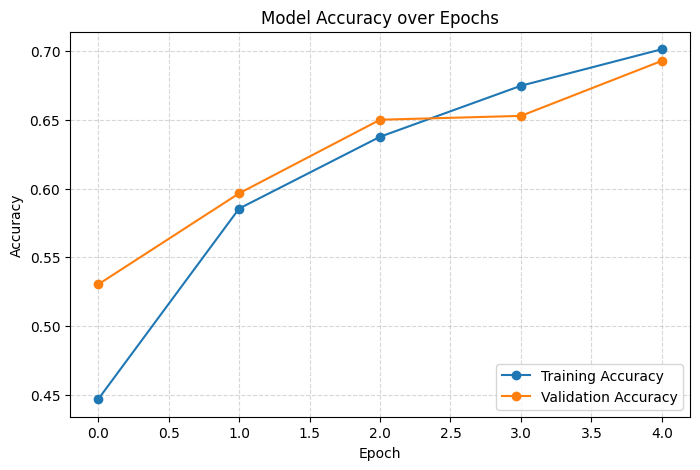

In [2]:
import matplotlib.pyplot as plt

# Plot training & validation accuracy values
plt.figure(figsize=(8, 5))
plt.plot(history.history['accuracy'], label='Training Accuracy', marker='o')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy', marker='o')
plt.title('Model Accuracy over Epochs')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step


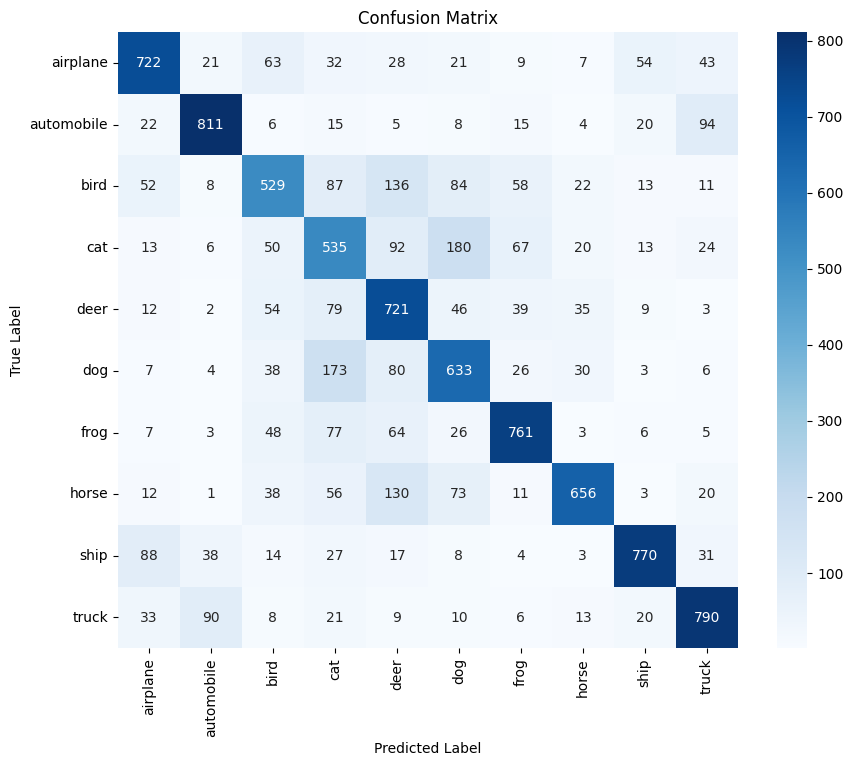

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 1. Get predictions for the entire test dataset
test_predictions = model.predict(test_images, verbose=1)
test_pred_labels = np.argmax(test_predictions, axis=1)

# 2. Compute the confusion matrix
cm = confusion_matrix(test_labels, test_pred_labels)

# 3. Plot the confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()